# Q decay function

Translated from MATLAB source: `katlaGV/physics_sandbox_2023/Q_decay_function.m` (sandbox script).

Constant mass eruption rate `Qp` until the airborne tephra volume reaches `(1 - vol_frac)` of `q_t_tot`, then a Gaussian decay with timescale `tauPlumeDecay`.

MATLAB's `gv` / `gv.obs` structs are kept as `SimpleNamespace`s so names stay traceable. `IceCauldron` equivalents: `gv.obs.q_t_tot` ~ `V_t_max`, `gv.vol_frac` ~ `Q_decay_frac`, `gv.tPlumeDecay` ~ `t_Qdecay`.

In [1]:
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np

In [2]:
gv = SimpleNamespace(obs=SimpleNamespace())
gv.Qp = 5.4e7  # (kg/s)
gv.obs.q_t_tot       = 0.95e9*1.2*.5   # Estimated tephra flux for eruption first phase (m3?)
gv.vol_frac          = 0.3             # Remaining fraction of airborne tephra after which to force plume flux decay
gv.rho_t             = 1000            # (kg/m3)

Vdecay = (gv.obs.q_t_tot*(1-gv.vol_frac))  # ./(gv.A_c .* gv.G0); % Normalized airborne volume threshold

gv.tPlumeDecay = Vdecay * gv.rho_t / gv.Qp  # (s)
tTotal  = gv.obs.q_t_tot * gv.rho_t / gv.Qp * 2  # (s)

# tiGaussSwitch = find(Vt>=Vdecay,1,'first');

# gv.tPlumeDecay = t(tiGaussSwitch);
gv.tauPlumeDecay = (2 *gv.vol_frac * gv.obs.q_t_tot * gv.rho_t) / (np.sqrt(2*np.pi)*gv.Qp)  # .*gv.tau_m); % Plume flux decay timescale

In [3]:
#
nt = 501
t = np.linspace(0,tTotal,nt)
Qp = np.zeros(nt)
Qp[t<gv.tPlumeDecay] = gv.Qp
td = t>=gv.tPlumeDecay
Qp[td] = gv.Qp * np.exp(-(((t[td]-gv.tPlumeDecay)**2)/(2*gv.tauPlumeDecay**2)))
# qScale = exp(-(((t-Par.tPlumeDecay).^2)/(2*Par.tauPlumeDecay.^2)));

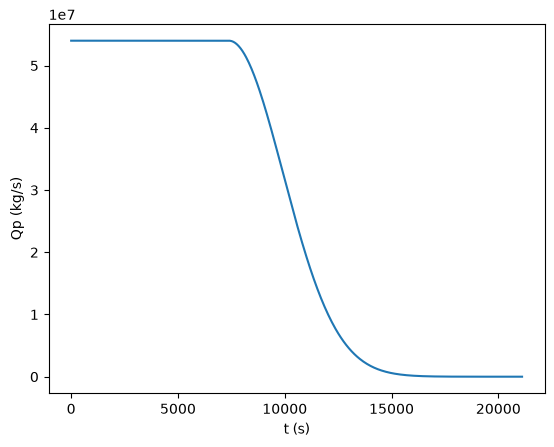

tPlumeDecay = 7389 s, tauPlumeDecay = 2527 s
erupted / q_t_tot = 1.0000


In [4]:
plt.figure()
plt.plot(t,Qp)
plt.xlabel("t (s)")
plt.ylabel("Qp (kg/s)")
plt.show()

# Check: erupted volume over the full window vs. q_t_tot (decay tail integrates to vol_frac/2 of it)
print(f"tPlumeDecay = {gv.tPlumeDecay:.4g} s, tauPlumeDecay = {gv.tauPlumeDecay:.4g} s")
print(f"erupted / q_t_tot = {np.trapezoid(Qp, t) / gv.rho_t / gv.obs.q_t_tot:.4f}")